# Original-catalog analysis

Actual archived Bell et al. observations, not the enhanced Song catalog. Outputs are computed and retained. Raw 8G, EC and PAYG waveforms have been acquired; S5 uses independently processed ground velocity. An independent 1543-candidate template-expanded catalog and GNSS processing are available; source memberships and exact regression agreement remain unverified.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if ROOT.name == 'report': ROOT = ROOT.parent
os.chdir(str(ROOT))
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
import pandas as pd
from src.visualization.figures import catalog_figures, conceptual_figure
df = pd.read_csv('results/catalogs/original_20180626.csv')
print('Original events:', len(df))
print(df.groupby('phase').size())
catalog_figures(df, 'results/figures')
conceptual_figure('results/figures')

Original events: 219
phase
1    29
2    74
3    72
4    44
dtype: int64


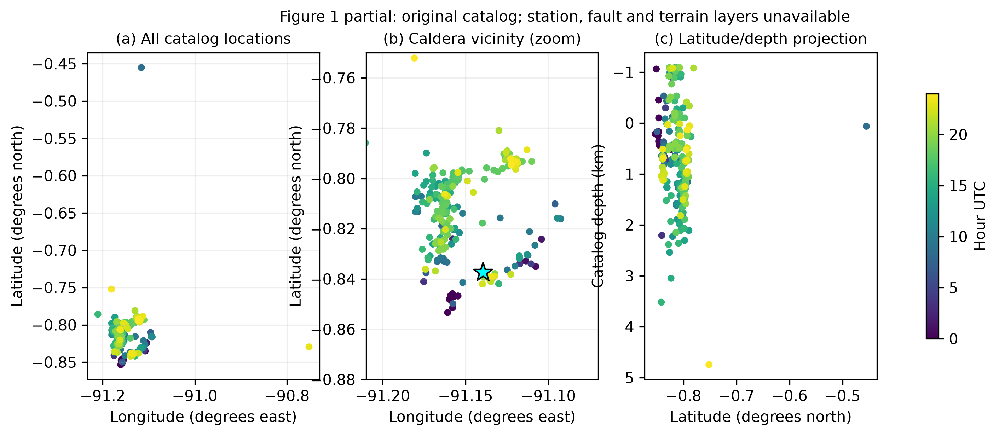

In [2]:
from IPython.display import Image, display
display(Image(filename='results/figures/fig01_original_catalog.png'))

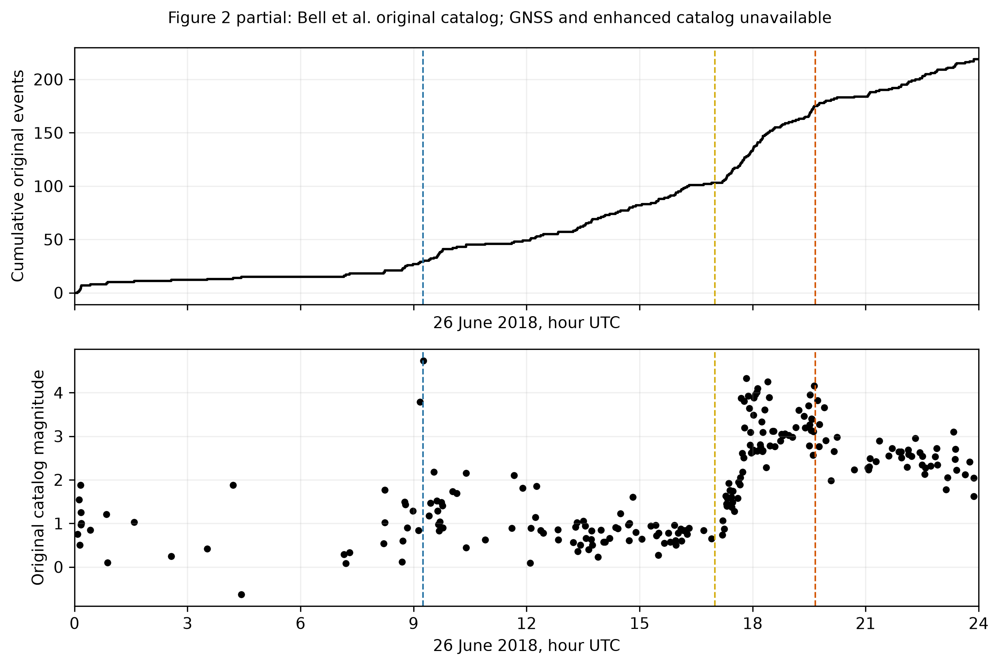

In [3]:
from IPython.display import Image, display
display(Image(filename='results/figures/fig02_original_timeline.png'))

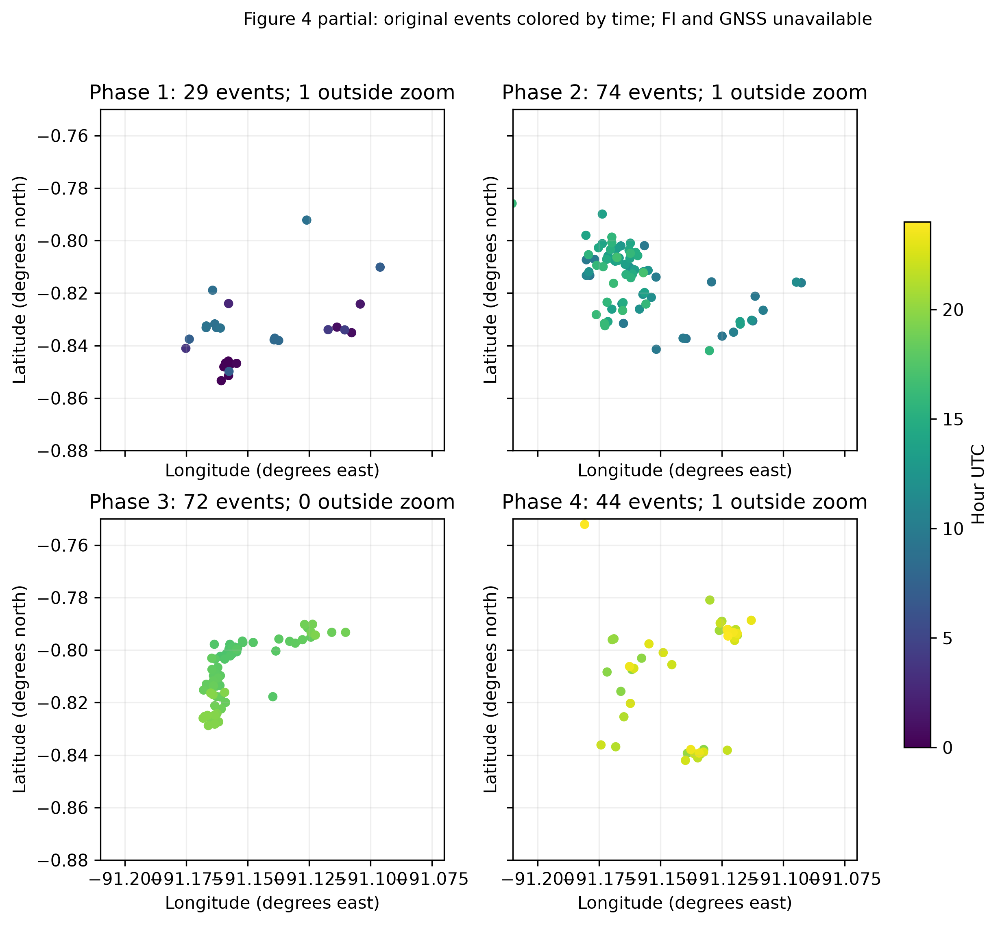

In [4]:
from IPython.display import Image, display
display(Image(filename='results/figures/fig04_original_phase_maps.png'))

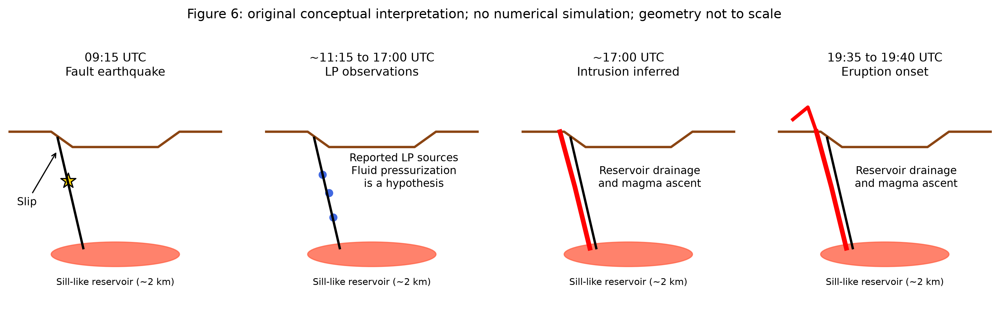

In [5]:
from IPython.display import Image, display
display(Image(filename='results/figures/fig06_conceptual_sequence.png'))

In [6]:
coverage = pd.read_csv('results/tables/waveform_coverage.csv')
print('Acquired channels:', len(coverage))
print(coverage.groupby('day_fraction').size())
print(pd.read_csv('results/tables/stations.csv').to_string(index=False))

Acquired channels: 21
day_fraction
1.0    21
dtype: int64
network station  latitude  longitude  elevation_m
     8G    SN01 -0.836980  -91.09129        884.0
     8G    SN03 -0.774290  -91.09002        707.0
     8G    SN04 -0.850070  -91.12921       1073.0
     8G    SN05 -0.851940  -91.14756       1045.0
     8G    SN07 -0.807190  -91.17005       1067.0
     8G    SN08 -0.852790  -91.19260        661.0
     8G    SN11 -0.802000  -91.12399        935.0
     8G    SN12 -0.811195  -91.13496        957.0
     8G    SN13 -0.619690  -91.07489         10.0
     8G    SN14 -0.843680  -91.15261        913.0


In [7]:
combined = pd.read_csv('results/tables/acquired_station_coverage.csv')
print('Combined acquired station coverage:')
print(combined.to_string(index=False))
print('EC observations are picked; nine-station association is a separate coverage experiment.')

Combined acquired station coverage:
network station  common_three_component_seconds  common_day_fraction
     8G    SN04                        86400.00             1.000000
     8G    SN05                        86400.00             1.000000
     8G    SN07                        86400.00             1.000000
     8G    SN11                        86400.00             1.000000
     8G    SN12                        86400.00             1.000000
     8G    SN13                        86400.00             1.000000
     8G    SN14                        86400.00             1.000000
     EC    SN02                        79636.67             0.921721
     EC    SN06                        86400.00             1.000000
EC observations are picked; nine-station association is a separate coverage experiment.


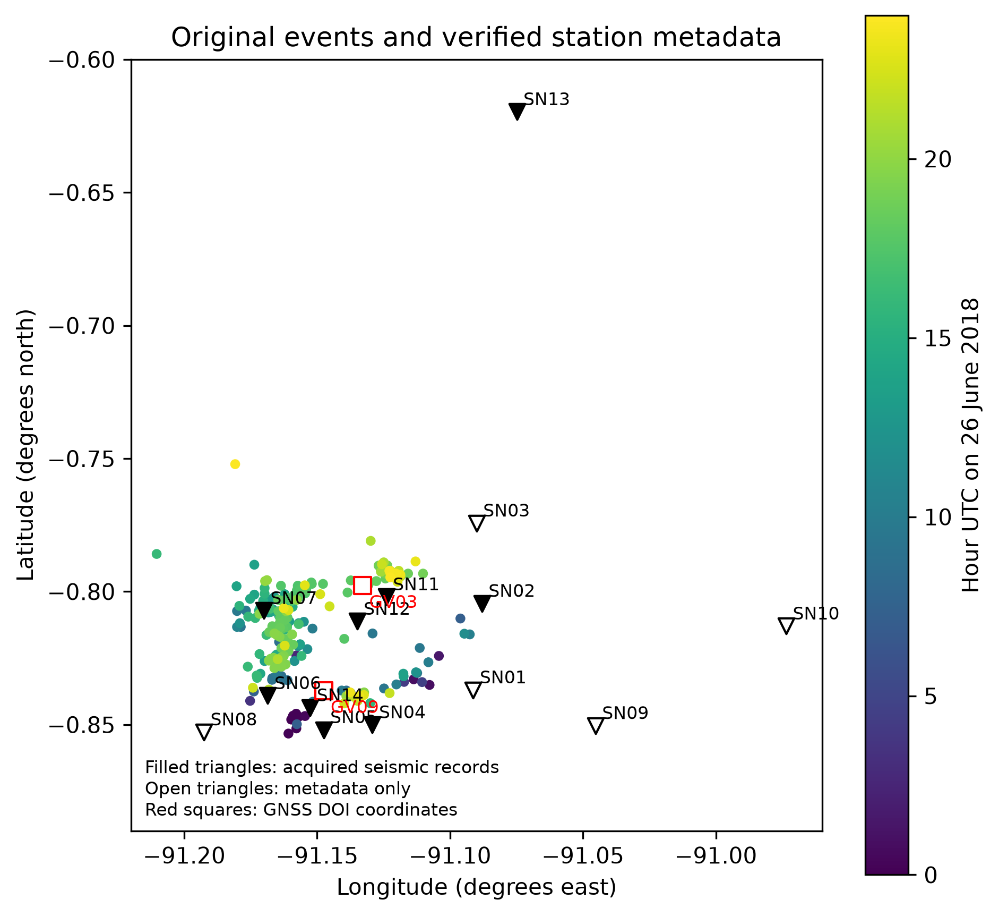

In [8]:
from IPython.display import Image, display
display(Image(filename='results/figures/fig01_all_stations.png'))

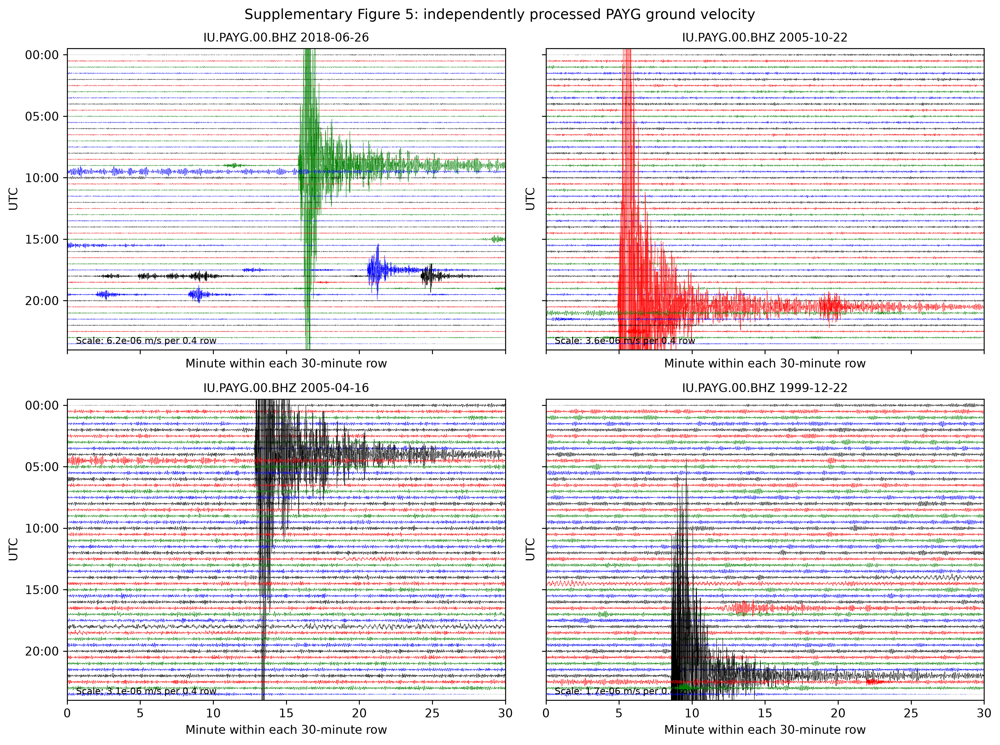

In [9]:
from IPython.display import Image, display
display(Image(filename='results/figures/figS05_payg_dayplots.png'))

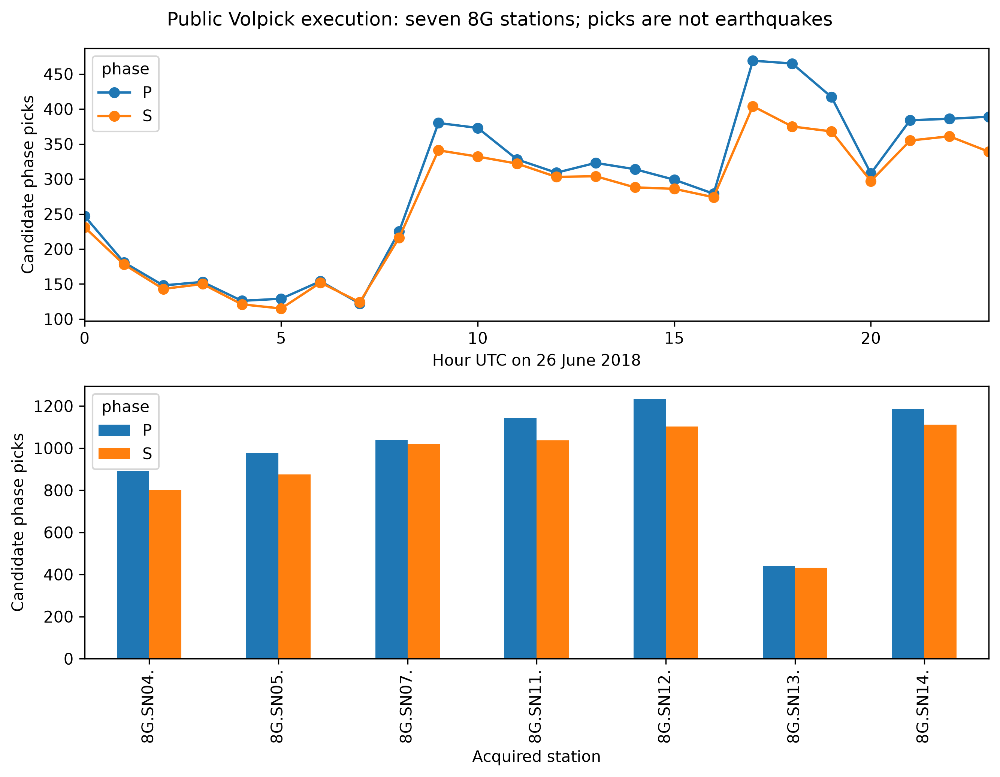

In [10]:
from IPython.display import Image, display
display(Image(filename='results/figures/phase_pick_counts.png'))

In [11]:
import json
execution = json.loads(Path('results/tables/volpick_execution.json').read_text())
print('Picking status:', execution['status'])
print('Candidate phase counts:', execution['phase_counts'])
print('These are phase picks, not associated earthquake events.')

Picking status: complete
Candidate phase counts: {'P': 6908, 'S': 6379}
These are phase picks, not associated earthquake events.


In [12]:
print('Separate VCH1 original entries:', len(pd.read_csv('results/catalogs/vch1_original_20180626.csv')))
print('VCH1 entries are not merged with the located catalog.')

Separate VCH1 original entries: 191
VCH1 entries are not merged with the located catalog.


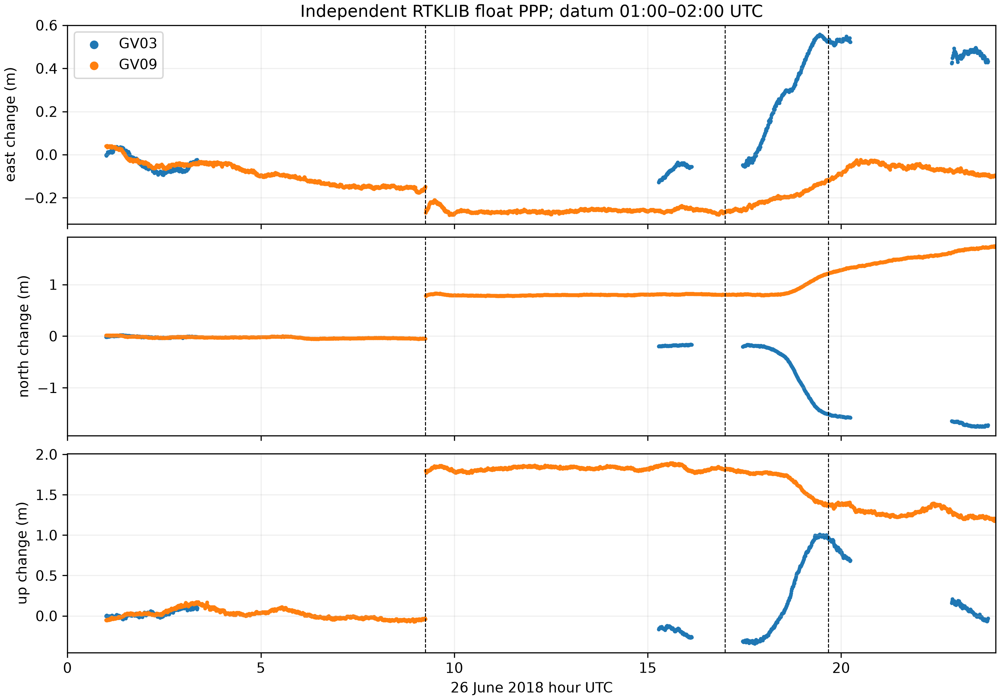

In [13]:
from IPython.display import Image, display
display(Image(filename='results/figures/gnss_independent_ppp.png'))

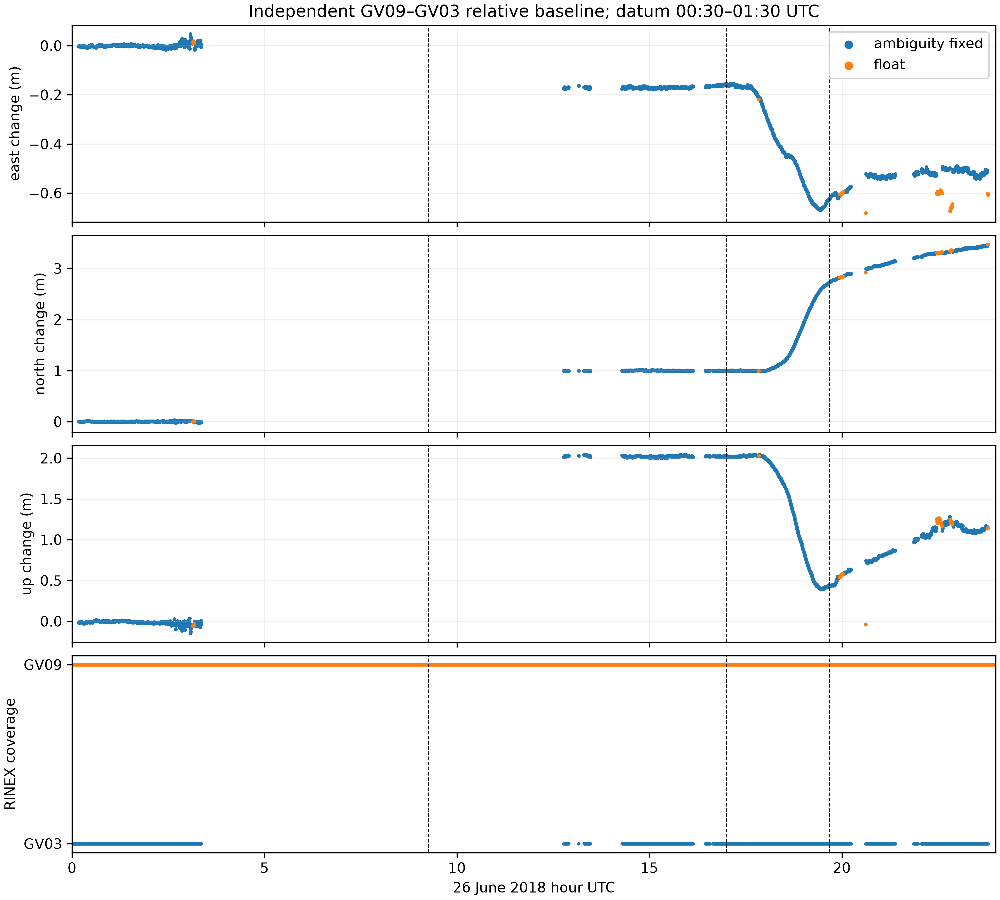

In [14]:
from IPython.display import Image, display
display(Image(filename='results/figures/gnss_relative_baseline.png'))

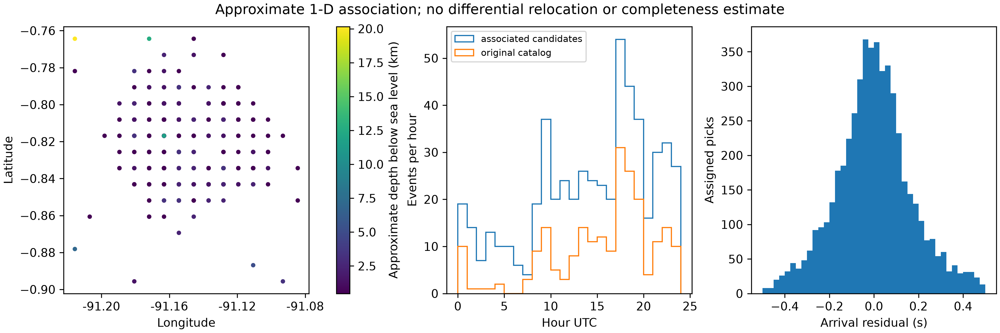

In [15]:
from IPython.display import Image, display
display(Image(filename='results/figures/approximate_association.png'))

In [16]:
import json
print(json.dumps(json.loads(Path('results/tables/gnss_ppp_analysis.json').read_text()), indent=2))
print('Independent PPP; original GIPSY settings differ. VCH1 skipped; GV03 lacks earthquake interval.')

{
  "method": "RTKLIB 2.4.2 forward GPS-only float PPP",
  "stations": [
    {
      "station": "GV03",
      "solution_epochs": 1431,
      "ppp_quality_epochs": 1431,
      "screened_epochs": 836,
      "screen": "Q=6, >=5 satellites, >=1 hour after gap >300 s",
      "reference_utc": [
        "2018-06-26T01:00Z",
        "2018-06-26T02:00Z"
      ],
      "fault_earthquake": {
        "before_epochs": 0,
        "after_epochs": 0,
        "mean_difference_m": null,
        "before_std_m": null,
        "after_std_m": null
      },
      "intrusion": {
        "before_epochs": 17,
        "after_epochs": 66,
        "mean_difference_m": {
          "east_m": 0.050624616510223194,
          "north_m": -0.017602440710098977,
          "up_m": -0.055334321454014956
        },
        "before_std_m": {
          "east_m": 0.0032982771652872713,
          "north_m": 0.0047038369032773334,
          "up_m": 0.010155015031347378
        },
        "after_std_m": {
          "east_m": 0.039

In [17]:
print(json.dumps(json.loads(Path('results/tables/approximate_association.json').read_text()), indent=2))
print('Approximate associations, not original relocated enhanced catalog.')

{
  "events": 536,
  "assigned_picks": 5138,
  "raw_events_before_final_qc": 536,
  "raw_arrivals_before_final_qc": 5138,
  "assigned_P": 2730,
  "assigned_S": 2408,
  "median_absolute_residual_s": 0.09821176528930664,
  "max_absolute_residual_s": 0.49953460693359375,
  "model": "Tepp et al. 2014 Table 1 Model F; top grid value at -2 km",
  "interpolation": "piecewise linear",
  "speed_scale": 1.0,
  "depth_datum": "km below sea level",
  "elevation_correction": {
    "method": "PyOcto surface correction",
    "vp_km_s": 4.29,
    "vs_km_s": 2.38
  },
  "domain_lat": [
    -0.9,
    -0.76
  ],
  "domain_lon": [
    -91.22,
    -91.08
  ],
  "depth_km": [
    0,
    30
  ],
  "minimum_P": 4,
  "minimum_S": 1,
  "minimum_total": 5,
  "minimum_both_phase_stations": 0,
  "match_tolerance_s": 0.5,
  "duplicate_time_s": 2,
  "location_node_km": 1,
  "travel_time_grid_km": 0.1,
  "time_slice_s": 300,
  "n_threads": 16,
  "pick_time_span_s": 86376.53999996185,
  "pyocto_version": "0.2.0",
  "l

In [18]:
print(json.dumps(json.loads(Path('results/tables/velocity_sensitivity.json').read_text()), indent=2))

{
  "nominal_events": 536,
  "tests": [
    {
      "label": "velocity_slow",
      "speed_scale": 0.95,
      "events": 536,
      "change_from_nominal_events": 0,
      "mutual_time_matches_within_2s": 531,
      "median_horizontal_shift_km": 0.0,
      "p90_horizontal_shift_km": 1.3728497529926678,
      "median_absolute_depth_shift_km": 0.0,
      "p90_absolute_depth_shift_km": 0.9375,
      "removed_arrivals_final_qc": 2
    },
    {
      "label": "velocity_fast",
      "speed_scale": 1.05,
      "events": 534,
      "change_from_nominal_events": -2,
      "mutual_time_matches_within_2s": 530,
      "median_horizontal_shift_km": 0.0,
      "p90_horizontal_shift_km": 1.3728498335603063,
      "median_absolute_depth_shift_km": 0.0,
      "p90_absolute_depth_shift_km": 0.9375,
      "removed_arrivals_final_qc": 3
    }
  ],
  "interpretation": "Uniform P/S speed perturbations are declared sensitivity cases, not physical confidence intervals; time matches do not prove event identity"

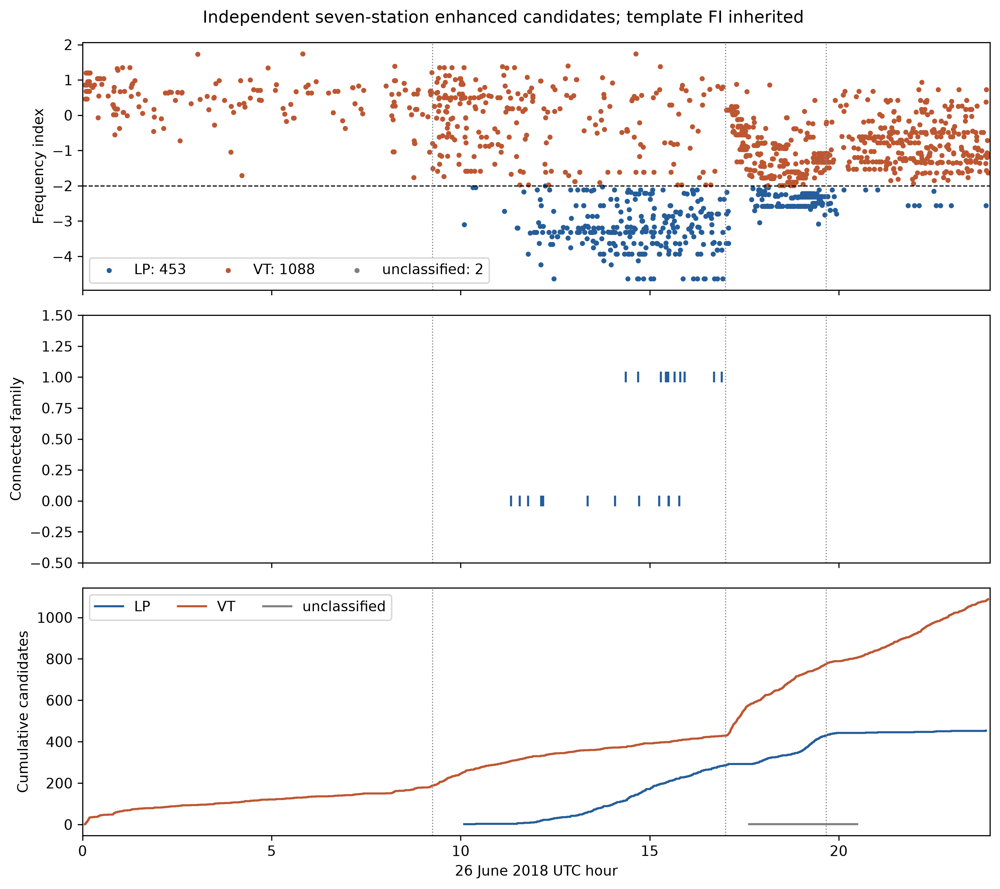

In [19]:
from IPython.display import Image, display
display(Image(filename='results/figures/enhanced_frequency_families.png'))

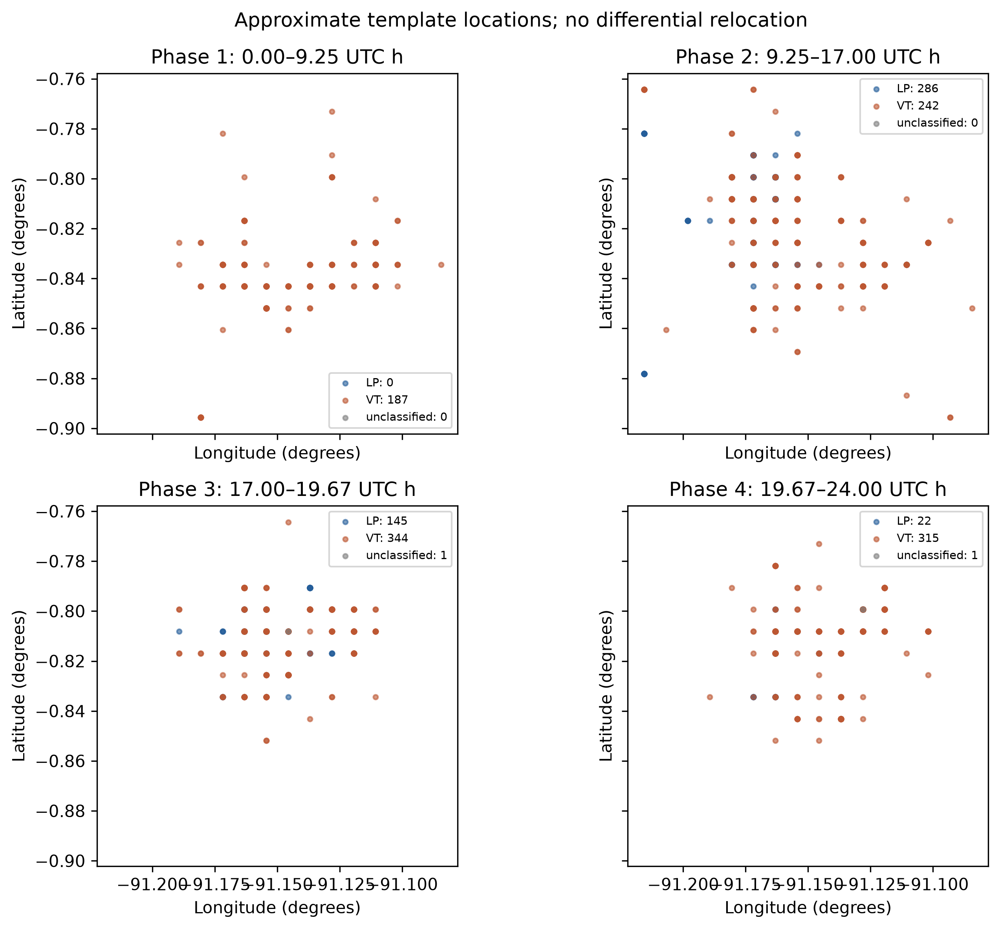

In [20]:
from IPython.display import Image, display
display(Image(filename='results/figures/enhanced_phase_maps.png'))

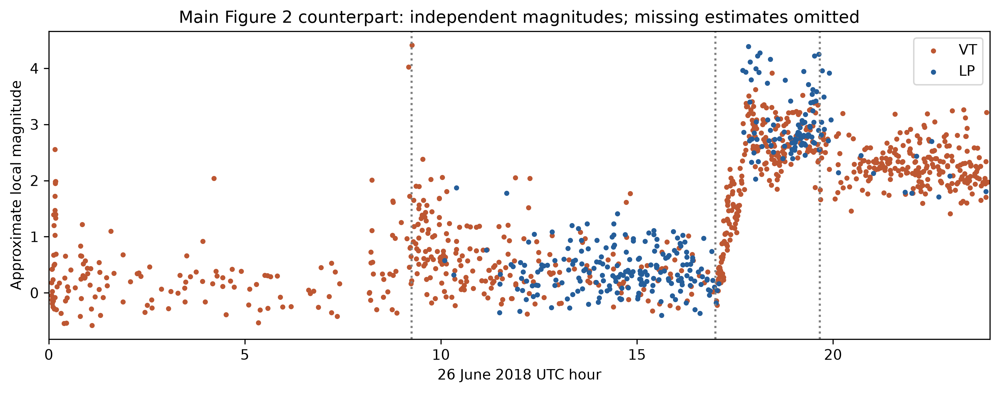

In [21]:
from IPython.display import Image, display
display(Image(filename='results/figures/enhanced_magnitude_timeline.png'))

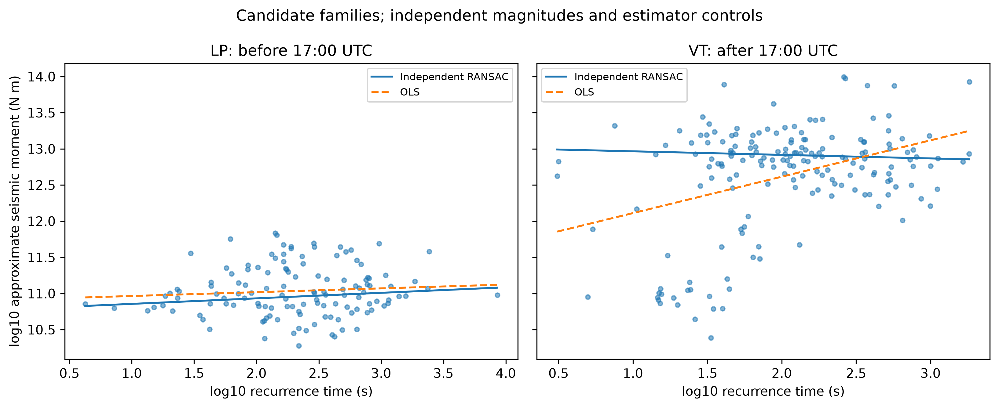

In [22]:
from IPython.display import Image, display
display(Image(filename='results/figures/enhanced_permissive_moment_recurrence.png'))

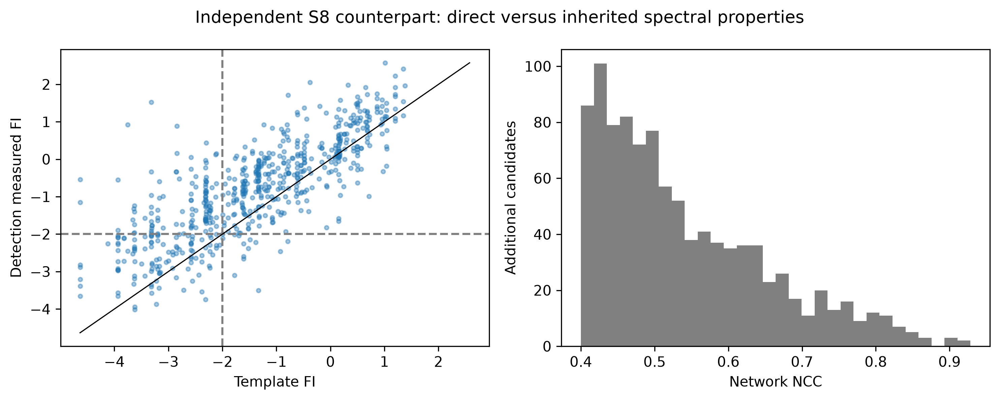

In [23]:
from IPython.display import Image, display
display(Image(filename='results/figures/supp_template_fi_comparison.png'))

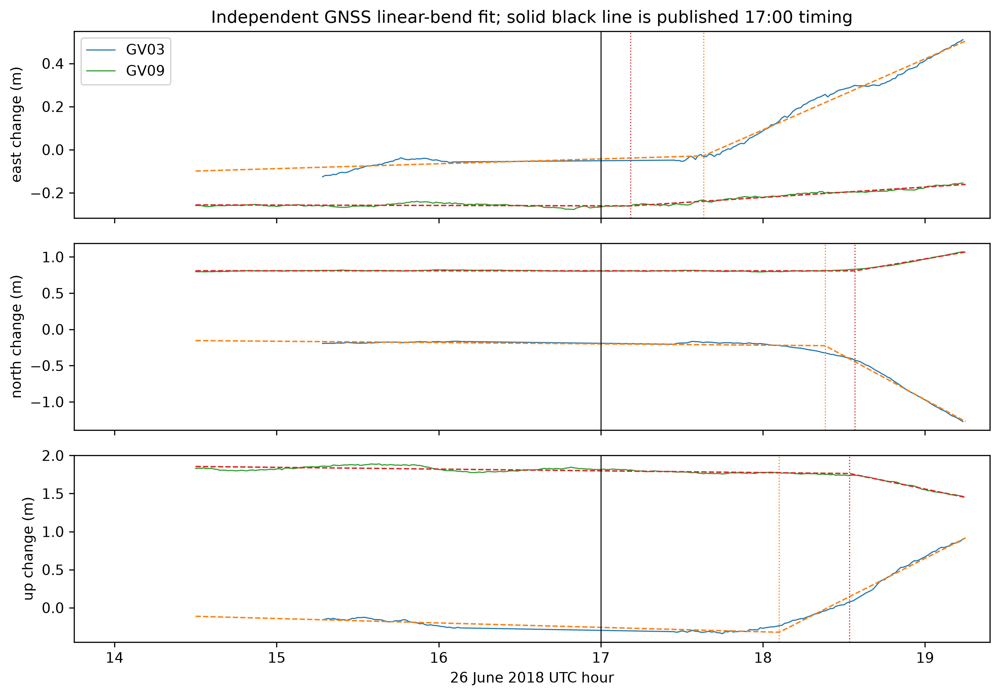

In [24]:
from IPython.display import Image, display
display(Image(filename='results/figures/gnss_intrusion_bend.png'))

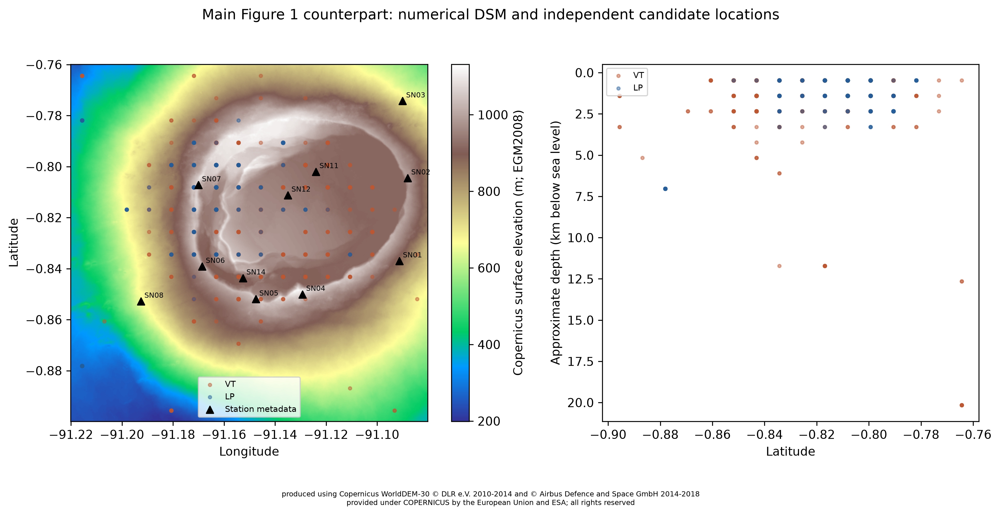

In [25]:
from IPython.display import Image, display
display(Image(filename='results/figures/enhanced_topographic_catalog.png'))

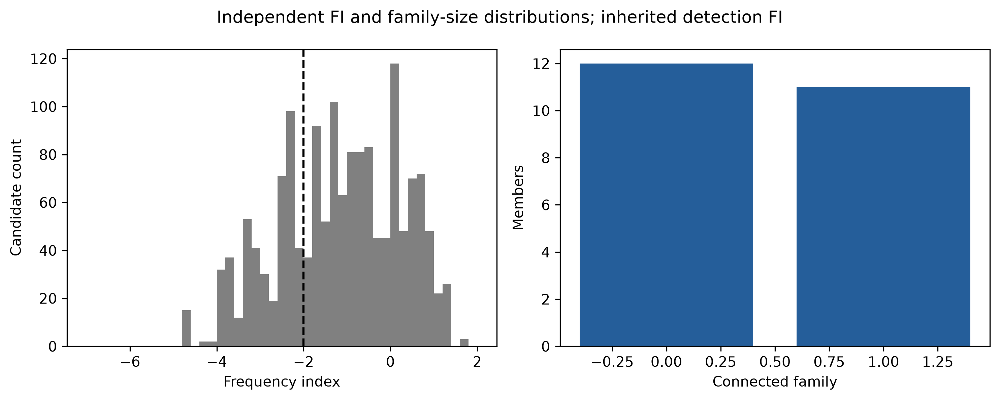

In [26]:
from IPython.display import Image, display
display(Image(filename='results/figures/supp_candidate_distributions.png'))

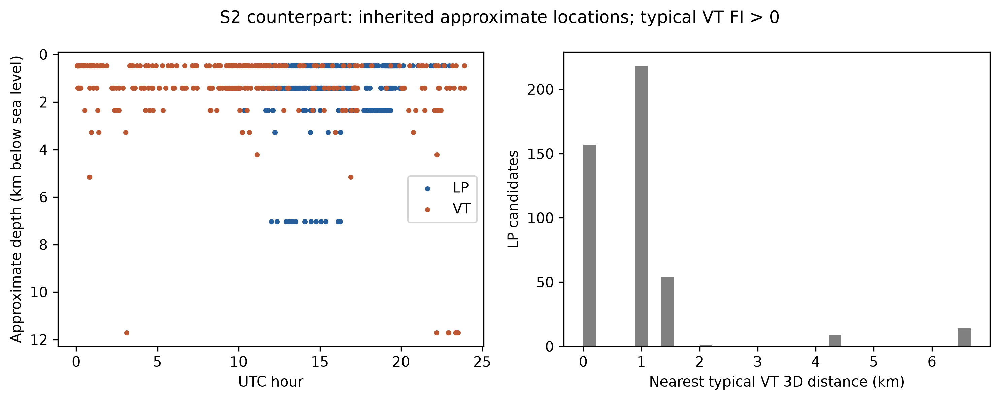

In [27]:
from IPython.display import Image, display
display(Image(filename='results/figures/supp_spatial_LP_VT.png'))

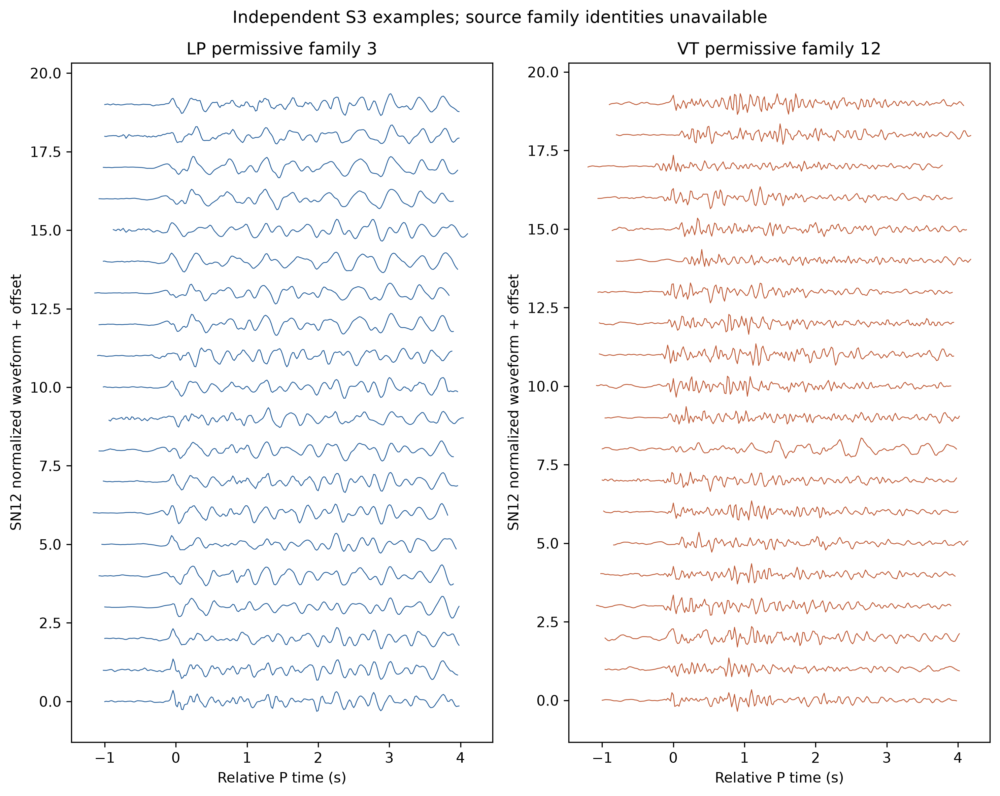

In [28]:
from IPython.display import Image, display
display(Image(filename='results/figures/supp_family_waveforms.png'))

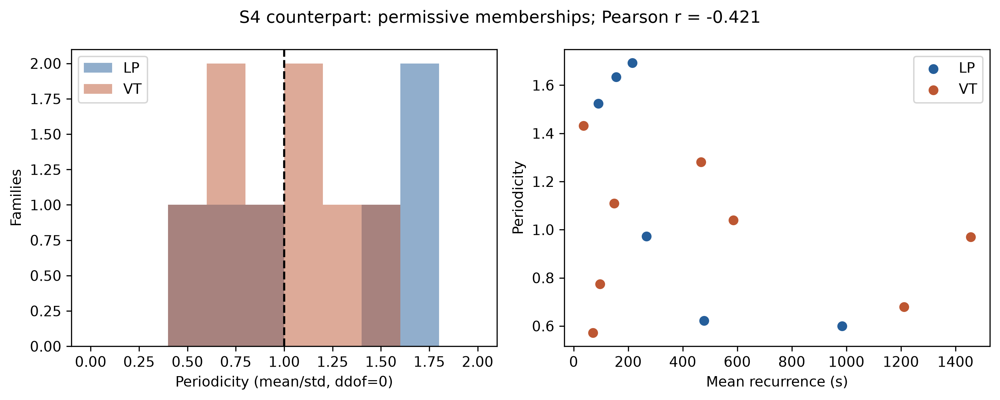

In [29]:
from IPython.display import Image, display
display(Image(filename='results/figures/supp_family_periodicity.png'))

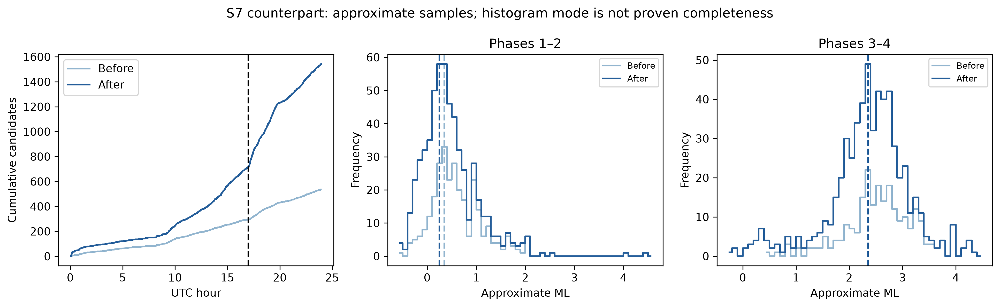

In [30]:
from IPython.display import Image, display
display(Image(filename='results/figures/supp_before_after_matching.png'))

In [31]:
print(json.dumps(json.loads(Path('results/tables/template_matching_execution.json').read_text()), indent=2))

{
  "templates": 447,
  "raw_template_peaks": 5548,
  "additional_candidates": 1007,
  "additional_classes": {
    "VT": 650,
    "LP": 357
  },
  "self_recovered": 447,
  "self_audited": 447,
  "minimum_self_ncc": 0.7178534884167007,
  "maximum_self_time_error_s": 0.0177842235571006,
  "MAD": "median(abs(network mean NCC)); EQcorrscan documented convention",
  "thresholds": "positive score >= max(9*MAD, 0.4)",
  "peak_separation_s": 2,
  "known_event_exclusion_s": 2,
  "network_weighting": "equal stations; mean available components within each",
  "limitations": [
    "Seven stations only",
    "Approximate template locations",
    "No undocumented spike rejection recreated",
    "Unvalidated additional candidates are not confirmed earthquakes",
    "No magnitudes",
    "All 536 known candidates excluded, not only selected templates"
  ]
}


In [32]:
print(json.dumps(json.loads(Path('results/tables/matched_window_execution.json').read_text()), indent=2))

{
  "new_events": 1007,
  "combined_candidates": 1543,
  "new_windows": 11949,
  "inherited_counts": {
    "VT": 650,
    "LP": 357
  },
  "measured_counts": {
    "VT": 519,
    "unclassified": 361,
    "LP": 127
  },
  "comparable_events": 646,
  "inherited_measured_agreement": 520,
  "velocity_processing": "hourly real-padded response-corrected 2-20 Hz continuous blocks",
  "limitations": [
    "Detection arrivals inherited, not repicked",
    "Primary classifications inherited from template per publication",
    "Direct FI uses available qualifying template channels, not all acquired channels",
    "Locations inherited; events not visually confirmed"
  ]
}


In [33]:
print(json.dumps(json.loads(Path('results/tables/nine_station_association.json').read_text()), indent=2))

{
  "events": 716,
  "assigned_picks": 7531,
  "velocity_source_doi": "10.1002/2013JB010227",
  "input_sha256": {
    "config/tepp2014_model_f.csv": "4ffe1be7d8c68eae11fc33bfacce18981df470fbec82443dfcf0639add939f02",
    "results/catalogs/combined_volpick_picks.csv": "1d7cd31cadb755da12237642a38200ee4fc07fe00f1d447511975a6cd9367c5f",
    "data/raw/stations.xml": "8728f3981f6e27013bdead675779e8f666c951daa897ca800df7179939759024",
    "data/raw/EC_responses.xml": "f8cd10554be0182b7c212991d06273f2e687545cdb02c48c76bfac39e214cfd4"
  },
  "raw_events_before_final_qc": 716,
  "raw_arrivals_before_final_qc": 7532,
  "assigned_P": 4007,
  "assigned_S": 3524,
  "median_absolute_residual_s": 0.10288357734680176,
  "max_absolute_residual_s": 0.49953460693359375,
  "model": "Tepp et al. 2014 Table 1 Model F; top grid value at -2 km",
  "interpolation": "piecewise linear",
  "speed_scale": 1.0,
  "depth_datum": "km below sea level",
  "elevation_correction": {
    "method": "PyOcto surface correcti

In [34]:
print(json.dumps(json.loads(Path('results/tables/enhanced_family_execution.json').read_text()), indent=2))

{
  "events": 1543,
  "class_counts": {
    "VT": 1088,
    "LP": 453,
    "unclassified": 2
  },
  "families": 2,
  "family_events": 23,
  "primary_minimum_common_stations": 4,
  "primary_max_lag_s": 0.2,
  "NCC_threshold": 0.7,
  "minimum_family_size": 10,
  "station_weighting": "mean component scores within station, then equal mean across common stations",
  "limitations": [
    "Template classifications inherited; independent direct FI also provided",
    "Approximate locations only",
    "No manual waveform labels or calibration events",
    "Noise windows, SNR and lag convention are independent choices",
    "Minimum four common stations is an independent quality screen",
    "Anticorrelations require visual review",
    "No magnitudes or moment-recurrence fit"
  ]
}


In [35]:
print(json.dumps(json.loads(Path('results/tables/enhanced_permissive_family_execution.json').read_text()), indent=2))

{
  "common_stations_minimum": 1,
  "families": 14,
  "family_members": 452,
  "negative_candidates": 159,
  "limitations": "Permissive sensitivity only; some edges supported by one station, not source-confirmed membership"
}


In [36]:
print(json.dumps(json.loads(Path('results/tables/matched_magnitude_execution.json').read_text()), indent=2))

{
  "estimated_events": 1154,
  "total_candidates": 1543,
  "station_ratios": 1467,
  "relative_formula": "ML_detection = ML_template + 0.7 log10(alpha)",
  "ratio": "dominant eigenvector detection/template slope of centered two-waveform covariance; signed best lag within 0.2 s; positive NCC only",
  "aggregation": "median station relative ML; available SNR>=2 P/Z waveforms",
  "limitations": [
    "Independent PCA formulation; original implementation unavailable",
    "Approximate absolute template magnitudes",
    "Correlation-defined detections not visually confirmed",
    "No unpublished ratio or correlation quality thresholds imposed"
  ]
}


In [37]:
print(json.dumps(json.loads(Path('results/tables/observed_permissive_recurrence_execution.json').read_text()), indent=2))

{
  "common_station_screen": 1,
  "fits": [
    {
      "family_type": "LP",
      "pairing": "preceding",
      "estimator": "OLS",
      "slope": 0.05277756314042264,
      "intercept": 10.91181294911479,
      "r_squared": 0.0073382909817465225,
      "p_value": 0.33441478805852376,
      "jackknife_slope_se": 0.03929042184473706,
      "transform": "log10",
      "n": 129
    },
    {
      "family_type": "LP",
      "pairing": "preceding",
      "estimator": "RANSAC independent settings",
      "slope": 0.07646453941261065,
      "intercept": 10.779131490750467,
      "r_squared": -0.044887643043735714,
      "inlier_r_squared": 0.16622584326515177,
      "inliers": 66,
      "n": 129,
      "transform": "log10"
    },
    {
      "family_type": "LP",
      "pairing": "following",
      "estimator": "OLS",
      "slope": -0.04993040115545705,
      "intercept": 11.150853019545314,
      "r_squared": 0.005792887853715629,
      "p_value": 0.3912871910336783,
      "jackknife_slope_

In [38]:
print(json.dumps(json.loads(Path('results/tables/gnss_bend_execution.json').read_text()), indent=2))

{
  "primary": [
    {
      "station": "gv03",
      "component": "east",
      "start_utc_hour": 14.5,
      "end_utc_hour": 19.25,
      "bend_utc_hour": 17.633333333333464,
      "pre_slope_m_per_hour": 0.02252106514704233,
      "post_slope_m_per_hour": 0.32923192073787266,
      "rss_m2": 0.06733235537572203,
      "minutes": 160
    },
    {
      "station": "gv03",
      "component": "north",
      "start_utc_hour": 14.5,
      "end_utc_hour": 19.25,
      "bend_utc_hour": 18.383333333333503,
      "pre_slope_m_per_hour": -0.018055549469214047,
      "post_slope_m_per_hour": -1.2081598517516068,
      "rss_m2": 0.13805452167954457,
      "minutes": 160
    },
    {
      "station": "gv03",
      "component": "up",
      "start_utc_hour": 14.5,
      "end_utc_hour": 19.25,
      "bend_utc_hour": 18.100000000000154,
      "pre_slope_m_per_hour": -0.0582649577658816,
      "post_slope_m_per_hour": 1.0784686238496246,
      "rss_m2": 0.21345851680332917,
      "minutes": 160
    },

In [39]:
print(json.dumps(json.loads(Path('results/tables/family_periodicity_execution.json').read_text()), indent=2))

{
  "screen": "permissive one common station; >=10 member families",
  "families": 14,
  "family_types": {
    "VT": 8,
    "LP": 6
  },
  "mean_recurrence_periodicity_pearson_r": -0.42132435489931386,
  "p_value": 0.1335215130933414,
  "fisher_approximate_95_percent": [
    -0.7779877549220302,
    0.14071040523745063
  ],
  "family_bootstrap_95_percent": [
    -0.7766625381822309,
    -0.021605021615198325
  ],
  "bootstrap_replicates": 5000,
  "random_seed": 20261009,
  "first_direct_LP_at_least_four_P_stations": "2018-06-26 10:23:54.216292143+00:00",
  "limitations": [
    "Family membership is screen-sensitive",
    "Bootstrap conditional on these 14 computed families",
    "Missed events, station and magnitude errors not represented",
    "First qualifying spectrum is not physical onset"
  ]
}


In [40]:
print(json.dumps(json.loads(Path('results/tables/topographic_map_execution.json').read_text()), indent=2))

{
  "source_url": "https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_S01_00_W092_00_DEM/Copernicus_DSM_COG_10_S01_00_W092_00_DEM.tif",
  "sha256": "d0ff15fda50e4521717571c71908bee40ee344b6df54da6f47c9ceaa9d9358f0",
  "tile_shape": [
    3600,
    3600
  ],
  "spacing_degrees": [
    0.0002777777777777778,
    0.0002777777777777778
  ],
  "map_bounds": [
    -91.22,
    -0.9,
    -91.08,
    -0.76
  ],
  "map_elevation_min_m": 199.14227294921875,
  "map_elevation_max_m": 1132.0770263671875,
  "map_samples": 254016,
  "type": "Copernicus GLO-30 digital surface model, not reconstructed eruption topography",
  "attribution": "produced using Copernicus WorldDEM-30 \u00a9 DLR e.V. 2010-2014 and \u00a9 Airbus Defence and Space GmbH 2014-2018\nprovided under COPERNICUS by the European Union and ESA; all rights reserved",
  "license_url": "https://docs.sentinel-hub.com/api/latest/static/files/data/dem/resources/license/License-COPDEM-30.pdf",
  "limitations": [
    "DSM surface 

In [41]:
print(json.dumps(json.loads(Path('results/tables/template_control_execution.json').read_text()), indent=2))

{
  "control": "20 templates, 10 LP and 10 VT, independently phase-randomized per channel while preserving individual Fourier amplitude spectra",
  "seed": 20261009,
  "templates": 20,
  "station_hours": 168,
  "raw_control_peaks": 0,
  "thresholds": "same positive max(9*MAD,0.4) as actual search",
  "limitations": [
    "Tests waveform-shape specificity, not earthquake false-positive rate",
    "Independent channel phases remove network coherence",
    "A smaller control library than real 447 templates; counts not directly scaled"
  ]
}


In [42]:
print(pd.read_csv('results/tables/template_threshold_sensitivity.csv').to_string(index=False))

 MAD_multiplier  minimum_network_NCC  additional_candidates
              9                  0.4                   1007
              9                  0.5                    534
              9                  0.6                    276
              9                  0.7                    112
             12                  0.4                    981
             12                  0.5                    531
             12                  0.6                    276
             12                  0.7                    112
             15                  0.4                    881
             15                  0.5                    513
             15                  0.6                    270
             15                  0.7                    112


In [43]:
print(pd.read_csv('results/tables/heldout_station_validation.csv').to_string(index=False))

subset  tolerance_s             criterion  candidates  supported  null_mean  null_2_5_percentile  null_97_5_percentile  empirical_upper_tail_p
   all          0.2             any_phase        1543        484     26.230               17.000                36.000                0.001996
   all          0.2   at_least_two_phases        1543        232      3.526                0.000                 7.000                0.001996
   all          0.2  same_station_P_and_S        1543        193      2.878                0.000                 6.000                0.001996
   all          0.2 both_stations_P_and_S        1543          5      0.022                0.000                 0.000                0.001996
   new          0.2             any_phase        1007        145     17.578               10.000                26.000                0.001996
   new          0.2   at_least_two_phases        1007         44      2.378                0.000                 6.000                0.001996

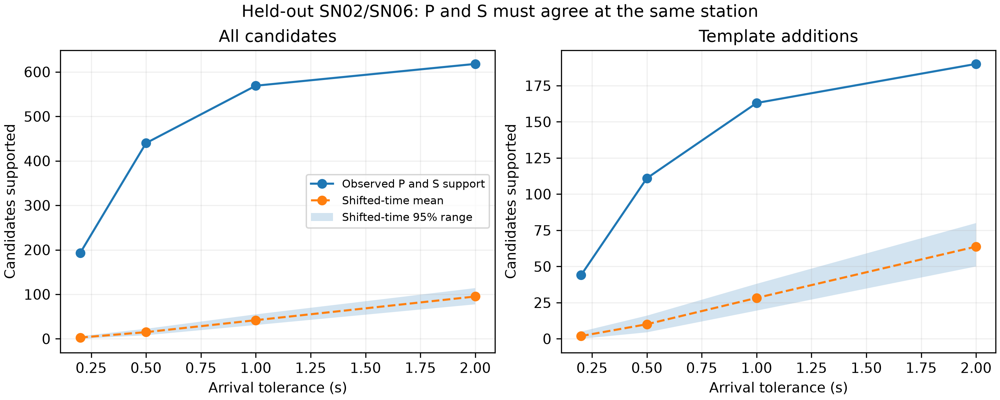

In [44]:
from IPython.display import Image, display
display(Image(filename='results/figures/heldout_station_validation.png'))

In [45]:
print(json.dumps(json.loads(Path('results/tables/hypodd_author_example.json').read_text()), indent=2))

{
  "source_revision": "fb40407fb768cbdc23a11e27bc841f5d4a98abb7",
  "example": "author example1, unchanged inputs",
  "events": 16,
  "max_horizontal_cartesian_difference_m": 0.8062257748298602,
  "max_depth_difference_m": 0.9999999999994458,
  "max_origin_seconds_field_difference_s": 0.0
}


In [46]:
print(json.dumps(json.loads(Path('results/tables/hypodd_ct_execution.json').read_text()), indent=2))

{
  "completed": true,
  "scientifically_accepted": false,
  "input_events": 716,
  "retained_events": 206,
  "not_retained_events": 510,
  "retained_within_initial_domain": 3,
  "clusters": {
    "1": 203,
    "2": 3
  },
  "median_horizontal_shift_km": 35.02162190773518,
  "maximum_horizontal_shift_km": 61.47261975744544,
  "median_absolute_depth_shift_km": 56.74375,
  "depth_range_km": [
    5.753,
    71.375
  ],
  "zero_depth_warnings": 503,
  "policy": "remove negative-depth event",
  "reason": "CT-only pilot with alternative velocity layering and settings; substantial location drift; not accepted as paper reproduction",
  "output_sha256": "03a1f55cc858c6802226c53d1ddfdcea12e97a728f74afadd2dff39fae42c3e4",
  "note": "Domain flag is diagnostic, not independent truth. -9 metadata omitted; formal LSQR errors are not bootstrap confidence intervals."
}


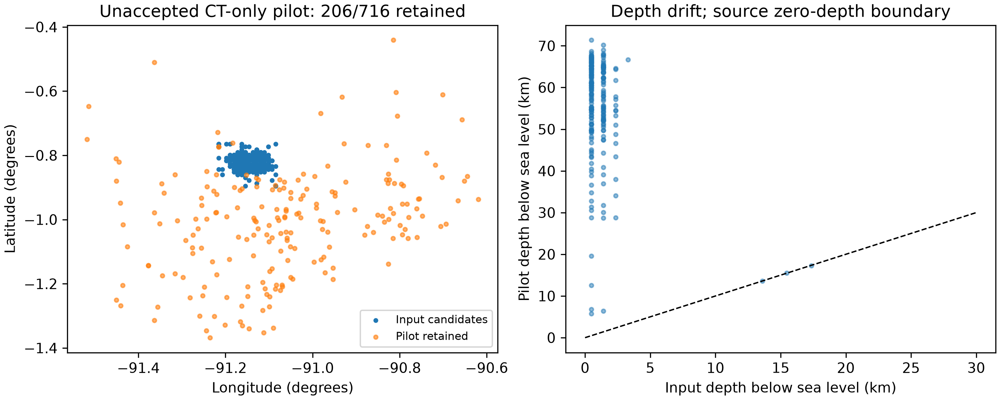

In [47]:
display(Image(filename='results/figures/hypodd_ct_audit.png'))

In [48]:
print(json.dumps(json.loads(Path('results/tables/hypodd_ct_keep_execution.json').read_text()), indent=2))

{
  "completed": true,
  "scientifically_accepted": false,
  "input_events": 716,
  "retained_events": 709,
  "not_retained_events": 7,
  "retained_within_initial_domain": 700,
  "clusters": {
    "1": 706,
    "2": 3
  },
  "median_horizontal_shift_km": 0.6237702561666081,
  "maximum_horizontal_shift_km": 110.62030429403009,
  "median_absolute_depth_shift_km": 0.35524999999999995,
  "depth_range_km": [
    0.001,
    58.684
  ],
  "zero_depth_warnings": 1219,
  "policy": "retain event, freeze negative depth update",
  "reason": "Boundary-sensitive CT-only pilot; native zero-depth step freezing; not validated as original relocation",
  "output_sha256": "a7ac3c1218063d67243958ac5f857afa60482d2168ad9615b441699490649621",
  "note": "Domain flag is diagnostic, not independent truth. -9 metadata omitted; formal LSQR errors are not bootstrap confidence intervals."
}


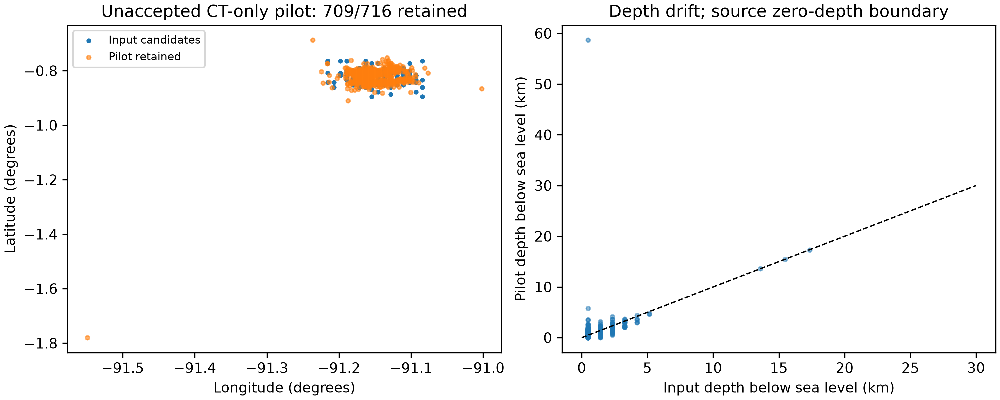

In [49]:
display(Image(filename='results/figures/hypodd_ct_keep_audit.png'))